In [31]:
import sys
import os
import pandas as pd

# Project root ko Python path mein add karna
project_root = os.path.abspath("..")
sys.path.append(project_root)

from Src.db_connection import get_connection

# SQL Server connection
conn = get_connection()

# Student Placement complete dataset
query = """
SELECT
    s.StudentID,
    s.StudentName,
    s.Course,
    s.Specialization,
    a.Marks10th,
    a.Marks12th,
    a.CGPA,
    sk.TechnicalSkills,
    sk.Certifications,
    p.ProjectCount,
    i.InternshipStatus,
    sc.CodingScore,
    sc.AptitudeScore,
    sc.CommunicationScore,
    pd.PlacementStatus
FROM Students s
LEFT JOIN AcademicDetails a
    ON s.StudentID = a.StudentID
LEFT JOIN Skills sk
    ON s.StudentID = sk.StudentID
LEFT JOIN Projects p
    ON s.StudentID = p.StudentID
LEFT JOIN Internships i
    ON s.StudentID = i.StudentID
LEFT JOIN Scores sc
    ON s.StudentID = sc.StudentID
LEFT JOIN PlacementDetails pd
    ON s.StudentID = pd.StudentID;
"""

# SQL Server se data Python DataFrame mein load
df = pd.read_sql(query, conn)

# Connection close
conn.close()

# First 5 records
df.head()

C:\Users\TEMP\AppData\Local\Temp\ipykernel_23272\4038375839.py:48: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,StudentID,StudentName,Course,Specialization,Marks10th,Marks12th,CGPA,TechnicalSkills,Certifications,ProjectCount,InternshipStatus,CodingScore,AptitudeScore,CommunicationScore,PlacementStatus
0,1,Aarav Sharma,B.Tech,Computer Science & Engineering,82.0,78.0,8.1,"Python, SQL, Power BI",SQL Certification,2,Yes,85.0,82.0,80.0,Placed
1,2,Aditya Verma,B.Tech,Computer Science & Engineering,76.0,81.0,8.2,"Java, SQL, Excel",Java Certification,1,Yes,72.0,68.0,75.0,Placed
2,3,Akash Negi,B.Tech,Computer Science & Engineering,88.0,85.0,8.7,"Python, SQL, Pandas",Python Certification,3,No,91.0,88.0,86.0,Placed
3,4,Ananya Gupta,B.Tech,Computer Science & Engineering,91.0,89.0,9.1,"Python, SQL, Machine Learning",Machine Learning Certification,2,Yes,64.0,70.0,68.0,Not Placed
4,5,Arjun Mehta,B.Tech,Information Technology,74.0,72.0,7.5,"Java, HTML, CSS",Web Development Certification,1,No,78.0,75.0,81.0,Placed


In [32]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (50, 15)

Column Names:
['StudentID', 'StudentName', 'Course', 'Specialization', 'Marks10th', 'Marks12th', 'CGPA', 'TechnicalSkills', 'Certifications', 'ProjectCount', 'InternshipStatus', 'CodingScore', 'AptitudeScore', 'CommunicationScore', 'PlacementStatus']

Data Types:
StudentID               int64
StudentName               str
Course                    str
Specialization            str
Marks10th             float64
Marks12th             float64
CGPA                  float64
TechnicalSkills           str
Certifications            str
ProjectCount            int64
InternshipStatus          str
CodingScore           float64
AptitudeScore         float64
CommunicationScore    float64
PlacementStatus           str
dtype: object

Missing Values:
StudentID             0
StudentName           0
Course                0
Specialization        0
Marks10th             0
Marks12th             0
CGPA                  0
TechnicalSkills       0
Certifications        0
ProjectCount  

In [33]:
# Check for duplicate records

duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 0


In [34]:
# Check categorical values for consistency

print("Internship Status:")
print(df["InternshipStatus"].value_counts())

print("\nPlacement Status:")
print(df["PlacementStatus"].value_counts())

Internship Status:
InternshipStatus
Yes    32
No     18
Name: count, dtype: int64

Placement Status:
PlacementStatus
Placed        32
Not Placed    18
Name: count, dtype: int64


In [35]:
# Check numerical value ranges

print("Marks10th range:", df["Marks10th"].min(), "to", df["Marks10th"].max())
print("Marks12th range:", df["Marks12th"].min(), "to", df["Marks12th"].max())
print("CGPA range:", df["CGPA"].min(), "to", df["CGPA"].max())
print("Coding Score range:", df["CodingScore"].min(), "to", df["CodingScore"].max())
print("Aptitude Score range:", df["AptitudeScore"].min(), "to", df["AptitudeScore"].max())
print("Communication Score range:", df["CommunicationScore"].min(), "to", df["CommunicationScore"].max())
print("Project Count range:", df["ProjectCount"].min(), "to", df["ProjectCount"].max())

Marks10th range: 67.0 to 94.0
Marks12th range: 69.0 to 92.0
CGPA range: 7.1 to 9.4
Coding Score range: 55.0 to 96.0
Aptitude Score range: 60.0 to 94.0
Communication Score range: 58.0 to 93.0
Project Count range: 1 to 3


In [36]:
# Create cleaned dataset

cleaned_df = df.copy()

# Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

# Remove rows with missing values
cleaned_df = cleaned_df.dropna()

# Reset index after cleaning
cleaned_df = cleaned_df.reset_index(drop=True)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", cleaned_df.shape)

Original Dataset Shape: (50, 15)
Cleaned Dataset Shape: (50, 15)


In [37]:
# FINAL DATA CLEANING

cleaned_df = df.copy()

# 1. Remove extra spaces from text columns
text_columns = [
    "StudentName",
    "Course",
    "Specialization",
    "TechnicalSkills",
    "Certifications",
    "InternshipStatus",
    "PlacementStatus"
]

for col in text_columns:
    cleaned_df[col] = cleaned_df[col].astype(str).str.strip()

# 2. Convert numerical columns to proper numeric datatype
numeric_columns = [
    "Marks10th",
    "Marks12th",
    "CGPA",
    "ProjectCount",
    "CodingScore",
    "AptitudeScore",
    "CommunicationScore"
]

for col in numeric_columns:
    cleaned_df[col] = pd.to_numeric(cleaned_df[col], errors="coerce")

# 3. Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

# 4. Handle missing values
cleaned_df = cleaned_df.dropna()

# 5. Reset index
cleaned_df = cleaned_df.reset_index(drop=True)

print("Before Cleaning:", df.shape)
print("After Cleaning :", cleaned_df.shape)
print("Missing Values After Cleaning:", cleaned_df.isnull().sum().sum())
print("Duplicate Records After Cleaning:", cleaned_df.duplicated().sum())

Before Cleaning: (50, 15)
After Cleaning : (50, 15)
Missing Values After Cleaning: 0
Duplicate Records After Cleaning: 0


In [38]:
# Display Before and After Cleaning

print("BEFORE CLEANING")
display(df.head())

print("\nAFTER CLEANING")
display(cleaned_df.head())

BEFORE CLEANING


,StudentID,StudentName,Course,Specialization,Marks10th,Marks12th,CGPA,TechnicalSkills,Certifications,ProjectCount,InternshipStatus,CodingScore,AptitudeScore,CommunicationScore,PlacementStatus
0,1,Aarav Sharma,B.Tech,Computer Science & Engineering,82.0,78.0,8.1,"Python, SQL, Power BI",SQL Certification,2,Yes,85.0,82.0,80.0,Placed
1,2,Aditya Verma,B.Tech,Computer Science & Engineering,76.0,81.0,8.2,"Java, SQL, Excel",Java Certification,1,Yes,72.0,68.0,75.0,Placed
2,3,Akash Negi,B.Tech,Computer Science & Engineering,88.0,85.0,8.7,"Python, SQL, Pandas",Python Certification,3,No,91.0,88.0,86.0,Placed
3,4,Ananya Gupta,B.Tech,Computer Science & Engineering,91.0,89.0,9.1,"Python, SQL, Machine Learning",Machine Learning Certification,2,Yes,64.0,70.0,68.0,Not Placed
4,5,Arjun Mehta,B.Tech,Information Technology,74.0,72.0,7.5,"Java, HTML, CSS",Web Development Certification,1,No,78.0,75.0,81.0,Placed



AFTER CLEANING


,StudentID,StudentName,Course,Specialization,Marks10th,Marks12th,CGPA,TechnicalSkills,Certifications,ProjectCount,InternshipStatus,CodingScore,AptitudeScore,CommunicationScore,PlacementStatus
0,1,Aarav Sharma,B.Tech,Computer Science & Engineering,82.0,78.0,8.1,"Python, SQL, Power BI",SQL Certification,2,Yes,85.0,82.0,80.0,Placed
1,2,Aditya Verma,B.Tech,Computer Science & Engineering,76.0,81.0,8.2,"Java, SQL, Excel",Java Certification,1,Yes,72.0,68.0,75.0,Placed
2,3,Akash Negi,B.Tech,Computer Science & Engineering,88.0,85.0,8.7,"Python, SQL, Pandas",Python Certification,3,No,91.0,88.0,86.0,Placed
3,4,Ananya Gupta,B.Tech,Computer Science & Engineering,91.0,89.0,9.1,"Python, SQL, Machine Learning",Machine Learning Certification,2,Yes,64.0,70.0,68.0,Not Placed
4,5,Arjun Mehta,B.Tech,Information Technology,74.0,72.0,7.5,"Java, HTML, CSS",Web Development Certification,1,No,78.0,75.0,81.0,Placed


In [39]:
# ============================================
# VISIBLE DATA CLEANING DEMO
# ============================================

demo_df = df.copy()

# Temporary missing values for demonstration
demo_df.loc[0, "CGPA"] = None
demo_df.loc[1, "CodingScore"] = None
demo_df.loc[2, "InternshipStatus"] = None

print("BEFORE CLEANING")
display(
    demo_df.loc[
        [0, 1, 2],
        ["StudentID", "CGPA", "CodingScore", "InternshipStatus"]
    ]
)

# Cleaning missing values
demo_df["CGPA"] = demo_df["CGPA"].fillna(demo_df["CGPA"].median())
demo_df["CodingScore"] = demo_df["CodingScore"].fillna(
    demo_df["CodingScore"].median()
)
demo_df["InternshipStatus"] = demo_df["InternshipStatus"].fillna("No")

print("AFTER CLEANING")
display(
    demo_df.loc[
        [0, 1, 2],
        ["StudentID", "CGPA", "CodingScore", "InternshipStatus"]
    ]
)

BEFORE CLEANING


,StudentID,CGPA,CodingScore,InternshipStatus
0,1,NaN,85.0,Yes
1,2,8.2,NaN,Yes
2,3,8.7,91.0,NaN


AFTER CLEANING


,StudentID,CGPA,CodingScore,InternshipStatus
0,1,8.3,85.0,Yes
1,2,8.2,76.0,Yes
2,3,8.7,91.0,No


In [40]:
# Final cleaned dataset save

cleaned_df.to_csv("../Data/cleaned_student_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [41]:
# Verify the saved cleaned dataset

cleaned_data = pd.read_csv("../Data/cleaned_student_data.csv")

print("Saved Dataset Shape:", cleaned_data.shape)

print("\nFirst 5 Records:")
display(cleaned_data.head())

print("\nMissing Values:")
print(cleaned_data.isnull().sum().sum())

Saved Dataset Shape: (50, 15)

First 5 Records:


,StudentID,StudentName,Course,Specialization,Marks10th,Marks12th,CGPA,TechnicalSkills,Certifications,ProjectCount,InternshipStatus,CodingScore,AptitudeScore,CommunicationScore,PlacementStatus
0,1,Aarav Sharma,B.Tech,Computer Science & Engineering,82.0,78.0,8.1,"Python, SQL, Power BI",SQL Certification,2,Yes,85.0,82.0,80.0,Placed
1,2,Aditya Verma,B.Tech,Computer Science & Engineering,76.0,81.0,8.2,"Java, SQL, Excel",Java Certification,1,Yes,72.0,68.0,75.0,Placed
2,3,Akash Negi,B.Tech,Computer Science & Engineering,88.0,85.0,8.7,"Python, SQL, Pandas",Python Certification,3,No,91.0,88.0,86.0,Placed
3,4,Ananya Gupta,B.Tech,Computer Science & Engineering,91.0,89.0,9.1,"Python, SQL, Machine Learning",Machine Learning Certification,2,Yes,64.0,70.0,68.0,Not Placed
4,5,Arjun Mehta,B.Tech,Information Technology,74.0,72.0,7.5,"Java, HTML, CSS",Web Development Certification,1,No,78.0,75.0,81.0,Placed



Missing Values:
0


In [42]:
# BASIC EDA

print("Dataset Information")
print("-------------------")
print("Total Students:", len(cleaned_data))
print("Total Features:", len(cleaned_data.columns))

print("\nPlacement Distribution")
print("----------------------")
print(cleaned_data["PlacementStatus"].value_counts())

Dataset Information
-------------------
Total Students: 50
Total Features: 15

Placement Distribution
----------------------
PlacementStatus
Placed        32
Not Placed    18
Name: count, dtype: int64


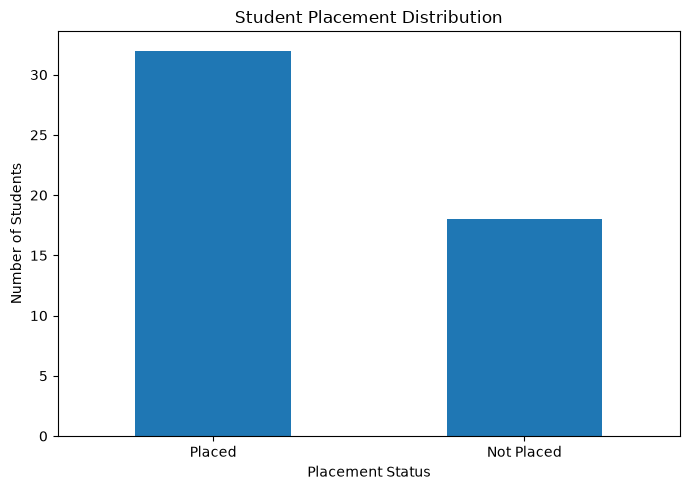

In [43]:
import matplotlib.pyplot as plt

placement_counts = cleaned_data["PlacementStatus"].value_counts()

plt.figure(figsize=(7, 5))
placement_counts.plot(kind="bar")

plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

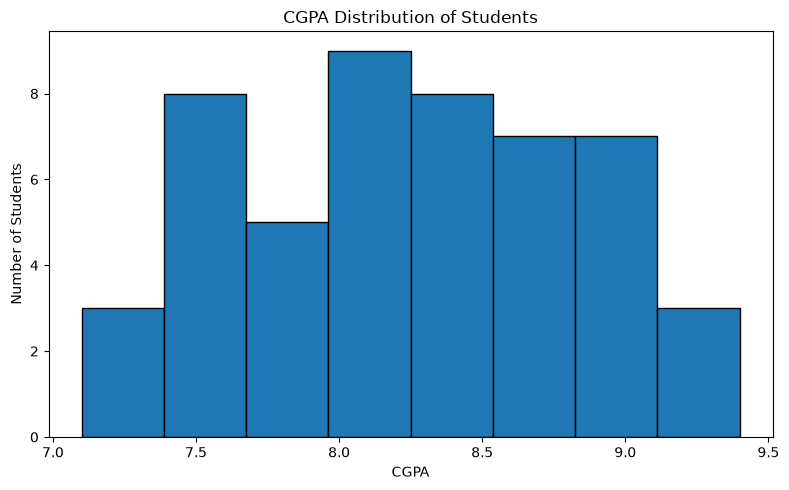

In [44]:
# CGPA Distribution

plt.figure(figsize=(8, 5))

plt.hist(cleaned_data["CGPA"], bins=8, edgecolor="black")

plt.title("CGPA Distribution of Students")
plt.xlabel("CGPA")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

PlacementStatus
Not Placed    7.977778
Placed        8.393750
Name: CGPA, dtype: float64


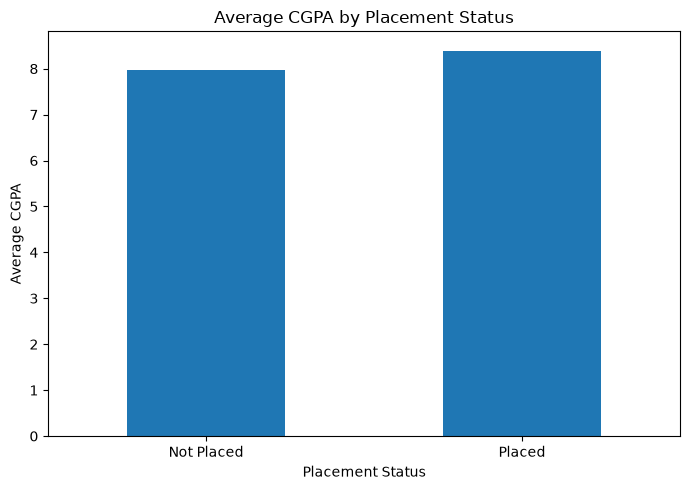

In [45]:
# Average CGPA by Placement Status

avg_cgpa = cleaned_data.groupby("PlacementStatus")["CGPA"].mean()

print(avg_cgpa)

plt.figure(figsize=(7, 5))
avg_cgpa.plot(kind="bar")

plt.title("Average CGPA by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Average CGPA")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

PlacementStatus
Not Placed    62.833333
Placed        83.468750
Name: CodingScore, dtype: float64


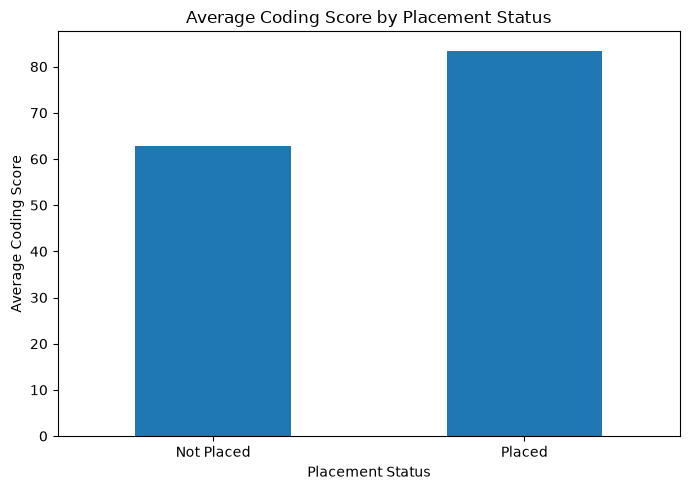

In [46]:
# Average Coding Score by Placement Status

avg_coding = cleaned_data.groupby("PlacementStatus")["CodingScore"].mean()

print(avg_coding)

plt.figure(figsize=(7, 5))
avg_coding.plot(kind="bar")

plt.title("Average Coding Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Average Coding Score")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Average Aptitude Score:
PlacementStatus
Not Placed    67.166667
Placed        82.531250
Name: AptitudeScore, dtype: float64


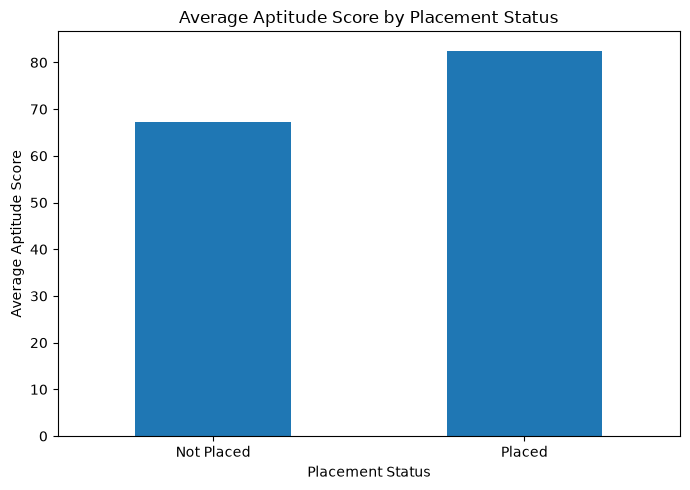


Graph Explanation:
The graph compares the average aptitude score of Placed and Not Placed students. The average score for Placed students is 82.53, while for Not Placed students it is 67.17.


In [47]:
# Average Aptitude Score by Placement Status

avg_aptitude = cleaned_data.groupby("PlacementStatus")["AptitudeScore"].mean()

print("Average Aptitude Score:")
print(avg_aptitude)

plt.figure(figsize=(7, 5))
avg_aptitude.plot(kind="bar")

plt.title("Average Aptitude Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Average Aptitude Score")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Explanation
placed_avg = avg_aptitude.get("Placed", 0)
not_placed_avg = avg_aptitude.get("Not Placed", 0)

print("\nGraph Explanation:")
print(
    f"The graph compares the average aptitude score of Placed and Not Placed students. "
    f"The average score for Placed students is {placed_avg:.2f}, "
    f"while for Not Placed students it is {not_placed_avg:.2f}."
)

Average Communication Score:
PlacementStatus
Not Placed    65.833333
Placed        83.531250
Name: CommunicationScore, dtype: float64


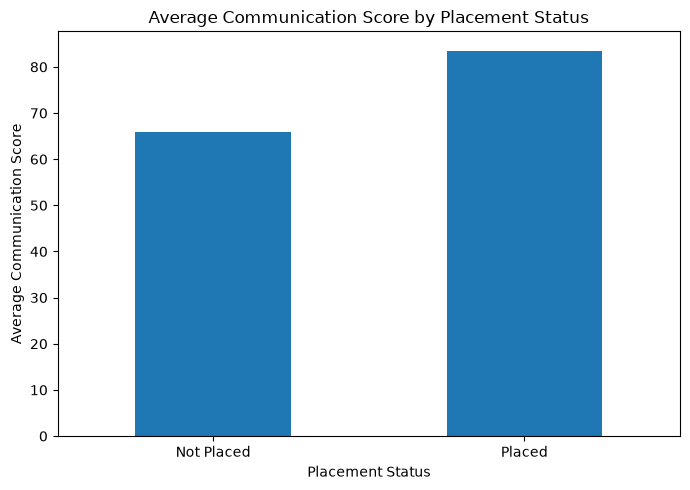


Graph Explanation:
The graph compares the average communication score of Placed and Not Placed students. The average score for Placed students is 83.53, while for Not Placed students it is 65.83.


In [48]:
# Average Communication Score by Placement Status

avg_communication = cleaned_data.groupby("PlacementStatus")["CommunicationScore"].mean()

print("Average Communication Score:")
print(avg_communication)

plt.figure(figsize=(7, 5))
avg_communication.plot(kind="bar")

plt.title("Average Communication Score by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Average Communication Score")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Explanation
placed_avg = avg_communication.get("Placed", 0)
not_placed_avg = avg_communication.get("Not Placed", 0)

print("\nGraph Explanation:")
print(
    f"The graph compares the average communication score of Placed and Not Placed students. "
    f"The average score for Placed students is {placed_avg:.2f}, "
    f"while for Not Placed students it is {not_placed_avg:.2f}."
)

In [49]:
# Summary Statistics

summary = cleaned_data[
    [
        "Marks10th",
        "Marks12th",
        "CGPA",
        "ProjectCount",
        "CodingScore",
        "AptitudeScore",
        "CommunicationScore"
    ]
].describe().round(2)

display(summary)

,Marks10th,Marks12th,CGPA,ProjectCount,CodingScore,AptitudeScore,CommunicationScore
count,50.00,50.00,50.00,50.00,50.00,50.00,50.00
mean,80.86,80.90,8.24,1.90,76.04,77.00,77.16
std,7.37,6.34,0.61,0.79,12.02,9.83,10.16
min,67.00,69.00,7.10,1.00,55.00,60.00,58.00
25%,75.25,76.00,7.72,1.00,66.25,69.25,69.00
50%,81.00,81.00,8.25,2.00,75.50,76.50,77.50
75%,86.75,86.00,8.78,2.75,86.75,85.75,86.00
max,94.00,92.00,9.40,3.00,96.00,94.00,93.00
